# Heart Failure — Árvore de Decisão, tratamento dos dados e MLflow

**Objetivo:** nesta etapa, avaliar apenas a **Árvore de Decisão** na base [Heart Failure Prediction (Kaggle)](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction), combinando **tratamento dos dados** e **ajuste de hiperparâmetros** para maximizar **acurácia, precisão e F1**, registrando todos os resultados no **MLflow** para apoiar a construção do relatório.

**Método**
- Split treino/teste estratificado (80/20). O teste só é usado depois da seleção.
- Zeros fisiologicamente impossíveis (`Cholesterol`, `RestingBP`) viram `NaN` e são imputados **dentro do pipeline** (ajustado apenas no treino de cada fold).
- A grade combina **tratamento dos dados** (estratégia de imputação e codificação categórica) com **hiperparâmetros da árvore**.
- Busca com validação cruzada estratificada repetida (5 folds × 2 repetições), refit por **F1 da classe 1**; acurácia, precisão e recall também são medidos na CV.
- O teste é avaliado com acurácia, precisão, recall, F1 e IC 95% por bootstrap.
- Cada configuração é registrada no MLflow (parâmetros, métricas, modelo e artefatos).
- **Ablação:** remoção de um atributo por vez (seleção de features), com acurácia, precisão, recall e F1 da classe 1.
- **Engenharia de features:** razões/interações clínicas comparadas com e sem.
- Cada execução grava seus resultados em `resultados/execucao_<timestamp>/`.
- Nota: árvores são **invariantes a transformações monotônicas** das variáveis (ex.: padronização), então o `StandardScaler` não altera o resultado — ele é mantido apenas por padronização do pipeline.

In [1]:
import os, json, zipfile, unicodedata, warnings
from pathlib import Path

os.environ['PYTHONWARNINGS'] = 'ignore'   # propaga aos workers do n_jobs=-1
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, GridSearchCV, RepeatedStratifiedKFold,
                                     ParameterGrid, cross_val_score)
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

import mlflow
import mlflow.sklearn

SEED = 42
print('scikit-learn', sklearn.__version__)
print('mlflow', mlflow.__version__)

scikit-learn 1.9.1
mlflow 3.17.2


In [2]:
from datetime import datetime

CANDIDATOS = [Path('heart.csv'), Path('bases/heart.csv')]
CSV = next((p for p in CANDIDATOS if p.exists()), None)
if CSV is None:
    raise FileNotFoundError('Coloque heart.csv na pasta do notebook ou em bases/heart.csv.')

# cada execução grava seus resultados em uma pasta própria
PASTA_EXECUCAO = Path('resultados') / f"execucao_{datetime.now():%Y%m%d_%H%M%S}"
PASTA_EXECUCAO.mkdir(parents=True, exist_ok=True)

MLFLOW_DB = Path('mlflow.db').resolve()
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB}')
EXPERIMENTO = 'heart_failure_arvore_decisao'
mlflow.set_experiment(EXPERIMENTO)

print('Base:', CSV.resolve())
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento:', EXPERIMENTO)
print('Pasta da execução:', PASTA_EXECUCAO.resolve())

Base: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/bases/heart.csv
Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento: heart_failure_arvore_decisao
Pasta da execução: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/resultados/execucao_20261022_093147


## Carga e limpeza dos dados

No `heart.csv` original não há `NaN`, mas `Cholesterol` tem muitos zeros (dado faltante codificado como 0) e `RestingBP` tem um. Aqui eles viram `NaN` e são tratados no pipeline.

In [3]:
df = pd.read_csv(CSV)
assert 'HeartDisease' in df.columns, 'Coluna HeartDisease não encontrada.'
print('Formato:', df.shape)
display(df.head())
print('Classes:\n', df['HeartDisease'].value_counts().to_string())
print('Valores ausentes (NaN):', int(df.isna().sum().sum()))
print('Linhas duplicadas:', int(df.duplicated().sum()))

# zeros impossíveis -> NaN (regra determinística, sem vazamento; imputação fica no pipeline)
for c in ['Cholesterol', 'RestingBP']:
    if c in df.columns:
        n0 = int((df[c] == 0).sum())
        print(f'{c}: {n0} zeros convertidos em NaN')
        df[c] = df[c].replace(0, np.nan)

Formato: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


Classes:
 HeartDisease
1    508
0    410
Valores ausentes (NaN): 0
Linhas duplicadas: 0
Cholesterol: 172 zeros convertidos em NaN
RestingBP: 1 zeros convertidos em NaN


## Preparação dos dados e estratégias de tratamento

O `ColumnTransformer` aplica:
- **Numéricas:** imputação (estratégia escolhida na grade) + padronização;
- **Categóricas:** codificação **one-hot** ou **ordinal** (comparadas na busca).

Tudo é ajustado **somente no treino** de cada fold (dentro do pipeline), sem vazamento.

In [4]:
X = df.drop(columns='HeartDisease')
y = df['HeartDisease']
cat = X.select_dtypes(include=['object', 'category']).columns.tolist()
num = X.select_dtypes(include='number').columns.tolist()
print('Numéricas:', num)
print('Categóricas:', cat)

def make_ohe():
    # compatível com scikit-learn >= 1.2 (sparse_output) e versões anteriores (sparse)
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)

def make_ordinal():
    return OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

def make_prep_cols(encoding='onehot', scaler='standard', imp_strategy='median',
                   num_cols=None, cat_cols=None):
    num_cols = num if num_cols is None else num_cols
    cat_cols = cat if cat_cols is None else cat_cols
    encoder = make_ohe() if encoding == 'onehot' else make_ordinal()
    sc = StandardScaler() if scaler == 'standard' else 'passthrough'
    transformadores = []
    if num_cols:
        transformadores.append(
            ('num', Pipeline([('imp', SimpleImputer(strategy=imp_strategy)),
                              ('sc', sc)]), num_cols))
    if cat_cols:
        transformadores.append(('cat', encoder, cat_cols))
    return ColumnTransformer(transformadores)

def make_prep(encoding='onehot', scaler='standard'):
    return make_prep_cols(encoding=encoding, scaler=scaler, imp_strategy='median',
                          num_cols=num, cat_cols=cat)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
print('Treino:', len(X_train), '| Teste:', len(X_test))
print('Proporção da classe 1 -> treino: %.3f | teste: %.3f' % (y_train.mean(), y_test.mean()))

Numéricas: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Categóricas: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Treino: 734 | Teste: 184
Proporção da classe 1 -> treino: 0.553 | teste: 0.554


## Busca de hiperparâmetros + tratamento dos dados

A grade combina o **tratamento dos dados** (estratégia de imputação) com os **hiperparâmetros da árvore**. Para cada codificação (one-hot e ordinal) é executado um `GridSearchCV` com **F1 da classe 1** como métrica de refit; acurácia, precisão e recall também são registradas na validação cruzada. Cada busca vira uma run no MLflow.

In [5]:
GRADE = {
    # tratamento dos dados
    'prep__num__imp__strategy': ['median', 'mean', 'most_frequent'],
    # hiperparâmetros da árvore
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__max_depth': [3, 5, 7, None],
    'modelo__min_samples_split': [2, 5, 10],
    'modelo__min_samples_leaf': [1, 3, 5],
    'modelo__max_features': [None, 'sqrt'],
    'modelo__class_weight': [None, 'balanced'],
}
SCORING = {'f1': 'f1', 'acuracia': 'accuracy', 'precisao': 'precision', 'recall': 'recall'}

ENCODINGS = ['onehot', 'ordinal']
resultados = {}

for enc in ENCODINGS:
    print(f'\n=== Codificação: {enc} ===')
    pipe = Pipeline([
        ('prep', make_prep(enc)),
        ('modelo', DecisionTreeClassifier(random_state=SEED)),
    ])
    busca = GridSearchCV(pipe, GRADE, cv=cv, scoring=SCORING, refit='f1',
                         n_jobs=-1, return_train_score=True, error_score='raise')
    with mlflow.start_run(run_name=f'arvore_{enc}') as run:
        busca.fit(X_train, y_train)
        i = busca.best_index_
        mlflow.log_param('encoding', enc)
        mlflow.log_param('n_combinacoes', len(ParameterGrid(GRADE)))
        mlflow.log_params({k: str(v) for k, v in busca.best_params_.items()})
        mlflow.log_metric('f1_cv', busca.best_score_)
        mlflow.log_metric('f1_cv_std', busca.cv_results_['std_test_f1'][i])
        mlflow.log_metric('f1_treino_cv', busca.cv_results_['mean_train_f1'][i])
        mlflow.log_metric('acuracia_cv', busca.cv_results_['mean_test_acuracia'][i])
        mlflow.log_metric('precisao_cv', busca.cv_results_['mean_test_precisao'][i])
        mlflow.log_metric('recall_cv', busca.cv_results_['mean_test_recall'][i])

        cv_path = PASTA_EXECUCAO / f'variacoes_arvore_{enc}.csv'
        pd.DataFrame(busca.cv_results_).to_csv(cv_path, index=False)
        mlflow.log_artifact(str(cv_path))
        mlflow.sklearn.log_model(
            busca.best_estimator_, name='modelo',
            skops_trusted_types=['numpy.dtype', 'sklearn.tree._tree.Tree'])

        resultados[enc] = {'busca': busca, 'run_id': run.info.run_id}

    print('Combinações:', len(ParameterGrid(GRADE)),
          '| fits:', len(ParameterGrid(GRADE)) * cv.get_n_splits())
    print('Melhor F1 (validação): %.4f ± %.4f' % (
        busca.best_score_, busca.cv_results_['std_test_f1'][i]))
    print('Acurácia (validação): %.4f | Precisão: %.4f | Recall: %.4f' % (
        busca.cv_results_['mean_test_acuracia'][i],
        busca.cv_results_['mean_test_precisao'][i],
        busca.cv_results_['mean_test_recall'][i]))
    print('F1 no treino da CV:    %.4f' % busca.cv_results_['mean_train_f1'][i])
    print('Melhores parâmetros:', busca.best_params_)


=== Codificação: onehot ===


Combinações: 864 | fits: 8640
Melhor F1 (validação): 0.8550 ± 0.0222
Acurácia (validação): 0.8426 | Precisão: 0.8742 | Recall: 0.8400
F1 no treino da CV:    0.8682
Melhores parâmetros: {'modelo__class_weight': 'balanced', 'modelo__criterion': 'entropy', 'modelo__max_depth': 3, 'modelo__max_features': None, 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 2, 'prep__num__imp__strategy': 'median'}

=== Codificação: ordinal ===


Combinações: 864 | fits: 8640
Melhor F1 (validação): 0.8604 ± 0.0318
Acurácia (validação): 0.8379 | Precisão: 0.8254 | Recall: 0.9002
F1 no treino da CV:    0.8658
Melhores parâmetros: {'modelo__class_weight': None, 'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 2, 'prep__num__imp__strategy': 'most_frequent'}


In [6]:
for enc, item in resultados.items():
    r = pd.DataFrame(item['busca'].cv_results_)
    col_rank = 'rank_test_f1' if 'rank_test_f1' in r.columns else 'rank_test_score'
    r = r.sort_values(col_rank).head(5)
    print(f'\nTop 5 — codificação {enc}')
    display(r[['params', 'mean_test_f1', 'std_test_f1',
               'mean_test_acuracia', 'mean_test_precisao',
               'mean_train_f1']].round(4))


Top 5 — codificação onehot


,params,mean_test_f1,std_test_f1,mean_test_acuracia,mean_test_precisao,mean_train_f1
667,"{'modelo__class_weight': 'balanced', 'modelo__...",0.855,0.0222,0.8426,0.8742,0.8679
664,"{'modelo__class_weight': 'balanced', 'modelo__...",0.855,0.0222,0.8426,0.8742,0.8679
665,"{'modelo__class_weight': 'balanced', 'modelo__...",0.855,0.0222,0.8426,0.8742,0.8679
666,"{'modelo__class_weight': 'balanced', 'modelo__...",0.855,0.0222,0.8426,0.8742,0.8679
661,"{'modelo__class_weight': 'balanced', 'modelo__...",0.855,0.0222,0.8426,0.8742,0.8679



Top 5 — codificação ordinal


,params,mean_test_f1,std_test_f1,mean_test_acuracia,mean_test_precisao,mean_train_f1
676,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8604,0.0318,0.8379,0.8254,0.8657
463,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8604,0.0318,0.8379,0.8254,0.8658
263,"{'modelo__class_weight': None, 'modelo__criter...",0.8604,0.0318,0.8379,0.8254,0.8657
461,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8604,0.0318,0.8379,0.8254,0.8658
460,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8604,0.0318,0.8379,0.8254,0.8658


## Avaliação no teste reservado

As métricas de teste são calculadas apenas depois da seleção e registradas nas mesmas runs do MLflow, junto com a matriz de confusão e as importâncias das variáveis.

In [7]:
def bootstrap_f1(y_true, pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        vals.append(f1_score(y_true[idx], pred[idx], zero_division=0))
    return np.percentile(vals, [2.5, 97.5])

def nomes_features(prep):
    return list(prep.get_feature_names_out())

linhas = []
for enc, item in resultados.items():
    busca = item['busca']
    pred = busca.predict(X_test)
    lo, hi = bootstrap_f1(y_test, pred)
    metricas = {
        'Acuracia_teste': float(accuracy_score(y_test, pred)),
        'Precisao_teste': float(precision_score(y_test, pred, zero_division=0)),
        'Recall_teste': float(recall_score(y_test, pred, zero_division=0)),
        'F1_teste': float(f1_score(y_test, pred, zero_division=0)),
        'F1_IC95_inf': float(lo),
        'F1_IC95_sup': float(hi),
    }
    i = busca.best_index_
    linhas.append({
        'Encoding': enc,
        'F1_CV': float(busca.best_score_),
        'Acuracia_CV': float(busca.cv_results_['mean_test_acuracia'][i]),
        'Precisao_CV': float(busca.cv_results_['mean_test_precisao'][i]),
        'Recall_CV': float(busca.cv_results_['mean_test_recall'][i]),
        **metricas,
    })

    with mlflow.start_run(run_id=item['run_id']):
        mlflow.log_metrics(metricas)

        # matriz de confusão
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
        ax.set_title(f'Árvore — codificação {enc}')
        fig.tight_layout()
        cm_path = PASTA_EXECUCAO / f'confusion_matrix_{enc}.png'
        fig.savefig(cm_path, dpi=150)
        plt.close(fig)
        mlflow.log_artifact(str(cm_path))

        # importâncias das variáveis
        modelo = busca.best_estimator_.named_steps['modelo']
        prep = busca.best_estimator_.named_steps['prep']
        imp = pd.Series(modelo.feature_importances_, index=nomes_features(prep))
        imp_path = PASTA_EXECUCAO / f'importancia_variaveis_{enc}.csv'
        imp.sort_values(ascending=False).to_csv(imp_path, header=['importancia'])
        mlflow.log_artifact(str(imp_path))

    print(f'\n=== {enc} ===')
    print(classification_report(y_test, pred, zero_division=0))

comparacao = pd.DataFrame(linhas).sort_values('F1_teste', ascending=False).reset_index(drop=True)
display(comparacao.round(4))


=== onehot ===
              precision    recall  f1-score   support

           0       0.77      0.85      0.81        82
           1       0.87      0.79      0.83       102

    accuracy                           0.82       184
   macro avg       0.82      0.82      0.82       184
weighted avg       0.83      0.82      0.82       184




=== ordinal ===
              precision    recall  f1-score   support

           0       0.84      0.71      0.77        82
           1       0.79      0.89      0.84       102

    accuracy                           0.81       184
   macro avg       0.82      0.80      0.80       184
weighted avg       0.81      0.81      0.81       184



,Encoding,F1_CV,Acuracia_CV,Precisao_CV,Recall_CV,Acuracia_teste,Precisao_teste,Recall_teste,F1_teste,F1_IC95_inf,F1_IC95_sup
0,ordinal,0.8604,0.8379,0.8254,0.9002,0.8098,0.7913,0.8922,0.8387,0.7817,0.8879
1,onehot,0.8550,0.8426,0.8742,0.8400,0.8207,0.8710,0.7941,0.8308,0.7650,0.8865


In [8]:
dummy = Pipeline([('prep', make_prep('onehot')),
                  ('modelo', DummyClassifier(strategy='most_frequent'))])
with mlflow.start_run(run_name='baseline_classe_majoritaria'):
    dummy.fit(X_train, y_train)
    pred_d = dummy.predict(X_test)
    lo_d, hi_d = bootstrap_f1(y_test, pred_d)
    metricas_d = {
        'Acuracia_teste': float(accuracy_score(y_test, pred_d)),
        'Precisao_teste': float(precision_score(y_test, pred_d, zero_division=0)),
        'Recall_teste': float(recall_score(y_test, pred_d, zero_division=0)),
        'F1_teste': float(f1_score(y_test, pred_d, zero_division=0)),
        'F1_IC95_inf': float(lo_d),
        'F1_IC95_sup': float(hi_d),
    }
    mlflow.log_param('modelo', 'DummyClassifier(most_frequent)')
    mlflow.log_metrics(metricas_d)

print('Baseline (classe majoritária):')
print(pd.Series(metricas_d).round(4).to_string())

Baseline (classe majoritária):
Acuracia_teste    0.5543
Precisao_teste    0.5543
Recall_teste      1.0000
F1_teste          0.7133
F1_IC95_inf       0.6471
F1_IC95_sup       0.7692


## Interpretação da árvore escolhida

Importâncias das variáveis, visualização da árvore final (profundidade limitada apenas na figura) e verificação da invariância à padronização.

Melhor codificação (F1 no teste): ordinal
Profundidade da árvore: 3 | folhas: 8


,importancia
cat__ExerciseAngina,0.4761
cat__ST_Slope,0.4378
cat__ChestPainType,0.0432
num__Cholesterol,0.0260
num__RestingBP,0.0169
num__Age,0.0000
num__FastingBS,0.0000
num__MaxHR,0.0000
num__Oldpeak,0.0000
cat__Sex,0.0000


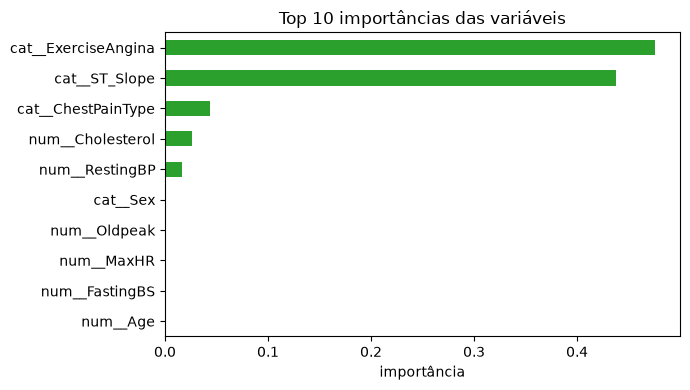

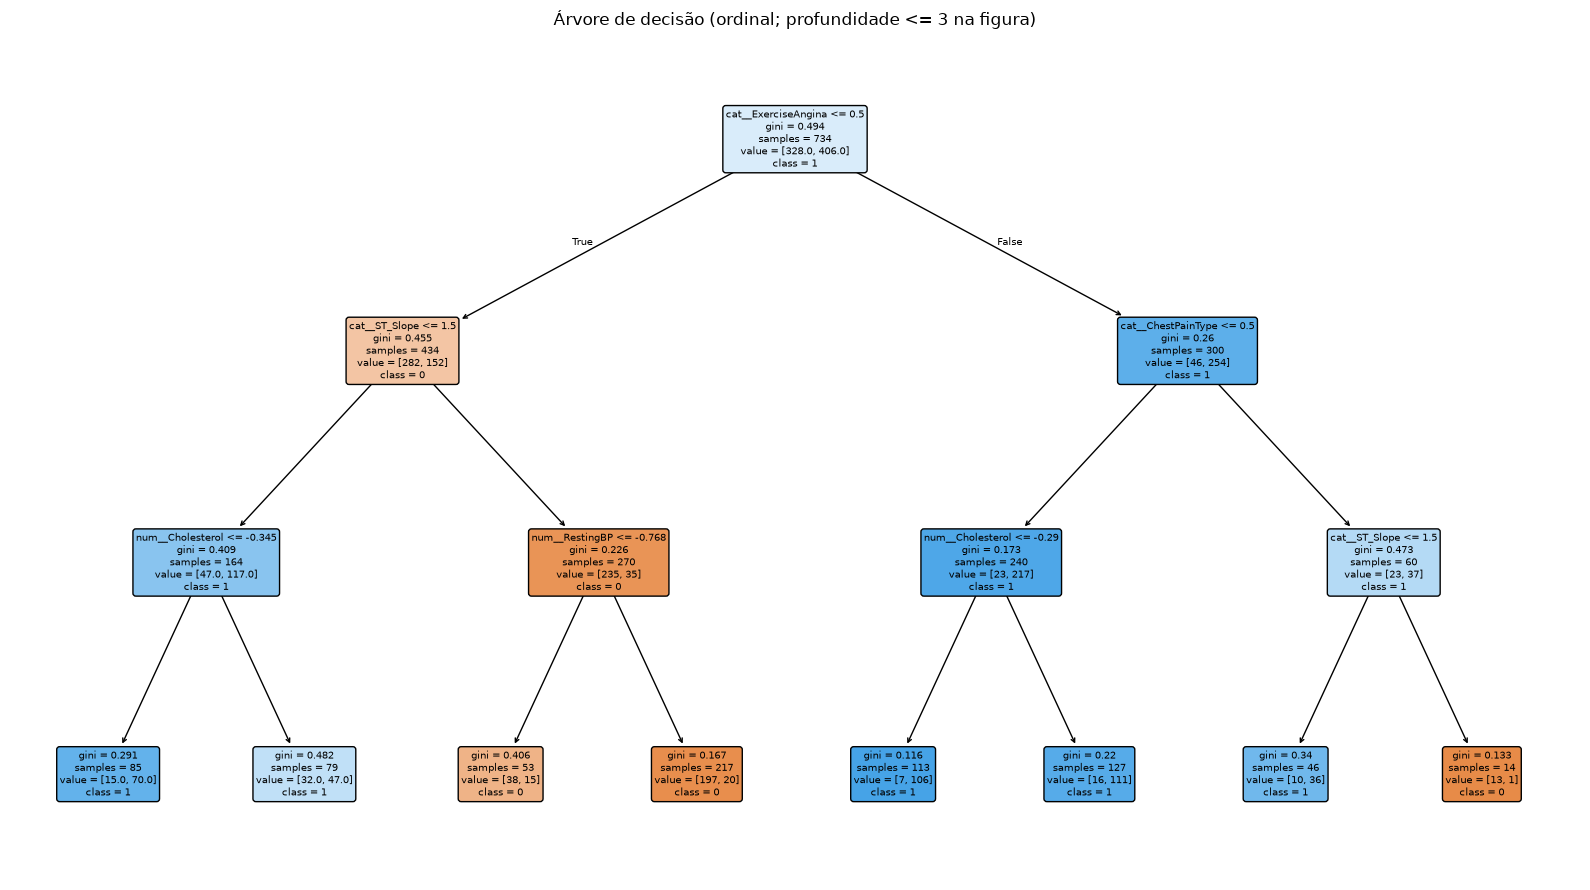

Predições idênticas com/sem StandardScaler: True


In [9]:
melhor_enc = comparacao.iloc[0]['Encoding']
busca = resultados[melhor_enc]['busca']
modelo = busca.best_estimator_.named_steps['modelo']
prep = busca.best_estimator_.named_steps['prep']
imp = pd.Series(modelo.feature_importances_, index=nomes_features(prep)).sort_values(ascending=False)

print('Melhor codificação (F1 no teste):', melhor_enc)
print('Profundidade da árvore:', modelo.get_depth(), '| folhas:', modelo.get_n_leaves())
display(imp.head(10).to_frame('importancia').round(4))

fig, ax = plt.subplots(figsize=(7, 4))
imp.head(10).sort_values().plot.barh(ax=ax, color='tab:green')
ax.set_title('Top 10 importâncias das variáveis')
ax.set_xlabel('importância')
fig.tight_layout()
fig.savefig(PASTA_EXECUCAO / 'importancia_variaveis_top10.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(16, 9))
plot_tree(modelo, feature_names=nomes_features(prep), class_names=['0', '1'],
          filled=True, rounded=True, max_depth=3, fontsize=7, ax=ax)
ax.set_title(f'Árvore de decisão ({melhor_enc}; profundidade <= 3 na figura)')
fig.tight_layout()
fig.savefig(PASTA_EXECUCAO / 'arvore_decisao.png', dpi=150)
plt.show()

# Verificação: árvores são invariantes à padronização
pred_com = busca.predict(X_test)
pipe_sem = Pipeline([('prep', make_prep(melhor_enc, scaler='none')),
                     ('modelo', clone(modelo))])
pipe_sem.set_params(prep__num__imp__strategy=busca.best_params_['prep__num__imp__strategy'])
pipe_sem.fit(X_train, y_train)
pred_sem = pipe_sem.predict(X_test)
print('Predições idênticas com/sem StandardScaler:',
      bool(np.array_equal(pred_com, pred_sem)))

## Ablação — seleção de atributos

Objetivo: verificar se **remover atributos** melhora o modelo (seleção de features).

- Para cada atributo, ele é removido do treino/teste e a árvore é reajustada com os **melhores hiperparâmetros** já encontrados (sem nova busca em grade, para manter a execução rápida).
- O cenário `todos` (sem remoção) serve de referência.
- A classe majoritária é a **1 (HeartDisease)**, com 55,3% dos registros; a métrica principal continua sendo o **F1 da classe 1**.
- As métricas exibidas são **acurácia, precisão, recall e F1** da classe 1.
- Cada cenário vira uma run filha no MLflow (run pai `ablacao_atributos`).

In [10]:
def metricas_teste(y_true, pred):
    return {
        'Acuracia': float(accuracy_score(y_true, pred)),
        'Precisao': float(precision_score(y_true, pred, pos_label=1, zero_division=0)),
        'Recall': float(recall_score(y_true, pred, pos_label=1, zero_division=0)),
        'F1': float(f1_score(y_true, pred, pos_label=1, zero_division=0)),
    }

# codificação usada na ablação: a de melhor F1 na validação cruzada
enc_abla = max(resultados, key=lambda e: resultados[e]['busca'].best_score_)
best_params = resultados[enc_abla]['busca'].best_params_
best_model_params = {k.replace('modelo__', ''): v
                     for k, v in best_params.items() if k.startswith('modelo__')}
imp_strategy = best_params['prep__num__imp__strategy']
print('Ablação usando encoding:', enc_abla)
print('Hiperparâmetros fixos:', best_model_params)
print('Estratégia de imputação fixa:', imp_strategy)

linhas_abla = []
with mlflow.start_run(run_name='ablacao_atributos'):
    for removido in [None] + list(X.columns):
        cols = [c for c in X.columns if c != removido]
        num_sub = [c for c in num if c in cols]
        cat_sub = [c for c in cat if c in cols]
        cenario = 'todos' if removido is None else f'sem_{removido}'

        params = dict(best_model_params)
        params['class_weight'] = None
        pipe = Pipeline([
            ('prep', make_prep_cols(enc_abla, imp_strategy=imp_strategy,
                                    num_cols=num_sub, cat_cols=cat_sub)),
            ('modelo', DecisionTreeClassifier(random_state=SEED, **params)),
        ])
        f1_cv = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring='f1').mean()
        pipe.fit(X_train[cols], y_train)
        pred = pipe.predict(X_test[cols])
        metricas = metricas_teste(y_test, pred)

        with mlflow.start_run(run_name=cenario, nested=True):
            mlflow.log_params({
                'atributo_removido': str(removido) if removido else 'nenhum',
                'encoding': enc_abla,
                'n_atributos': len(cols),
                'class_weight': 'None',
            })
            mlflow.log_metric('f1_cv', float(f1_cv))
            mlflow.log_metrics(metricas)

        linhas_abla.append({
            'Cenario': cenario,
            'Atributo_removido': removido or 'nenhum',
            **metricas,
        })
        print(f'{cenario}: ok')

ablacao = (pd.DataFrame(linhas_abla)
           .sort_values('F1', ascending=False)
           .reset_index(drop=True))
ablacao.to_csv(PASTA_EXECUCAO / 'ablacao_atributos.csv', index=False)
print('\nCenários ordenados por F1 no teste:')
display(ablacao.round(4))

Ablação usando encoding: ordinal
Hiperparâmetros fixos: {'class_weight': None, 'criterion': 'gini', 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
Estratégia de imputação fixa: most_frequent
todos: ok


sem_Age: ok
sem_Sex: ok


sem_ChestPainType: ok
sem_RestingBP: ok


sem_Cholesterol: ok
sem_FastingBS: ok


sem_RestingECG: ok
sem_MaxHR: ok


sem_ExerciseAngina: ok
sem_Oldpeak: ok


sem_ST_Slope: ok

Cenários ordenados por F1 no teste:


,Cenario,Atributo_removido,Acuracia,Precisao,Recall,F1
0,todos,nenhum,0.8098,0.7913,0.8922,0.8387
1,sem_RestingBP,RestingBP,0.8207,0.8876,0.7745,0.8272
2,sem_Cholesterol,Cholesterol,0.8207,0.8876,0.7745,0.8272
3,sem_FastingBS,FastingBS,0.8207,0.8876,0.7745,0.8272
4,sem_Age,Age,0.8152,0.8778,0.7745,0.8229
5,sem_ExerciseAngina,ExerciseAngina,0.7989,0.8736,0.7451,0.8042
6,sem_ST_Slope,ST_Slope,0.7772,0.8280,0.7549,0.7897
7,sem_MaxHR,MaxHR,0.7500,0.7414,0.8431,0.7890
8,sem_Sex,Sex,0.7391,0.7647,0.7647,0.7647
9,sem_ChestPainType,ChestPainType,0.7391,0.7647,0.7647,0.7647


## Engenharia de features (razões/interações clínicas)

A árvore faz cortes paralelos aos eixos; **razões** podem capturar relações "diagonais" que exigiriam vários cortes. Aqui comparamos o melhor modelo **sem** e **com** features clínicas derivadas:

- `FC_pct_teorica = MaxHR / (220 - Age)`
- `Chol_por_Idade = Cholesterol / Age`
- `BP_por_Idade = RestingBP / Age`
- `Oldpeak_por_FC = Oldpeak / MaxHR`
- `Angina_x_Oldpeak = (ExerciseAngina == 'Y') * Oldpeak`

As razões são calculadas linha a linha (sem vazamento) e entram no pipeline numérico. Cada cenário é registrado no MLflow.

In [11]:
# features clínicas derivadas (linha a linha, sem vazamento)
df_eng = df.copy()
df_eng['FC_pct_teorica']   = df_eng['MaxHR'] / (220 - df_eng['Age'])
df_eng['Chol_por_Idade']   = df_eng['Cholesterol'] / df_eng['Age']
df_eng['BP_por_Idade']     = df_eng['RestingBP'] / df_eng['Age']
df_eng['Oldpeak_por_FC']   = df_eng['Oldpeak'] / df_eng['MaxHR'].replace(0, np.nan)
df_eng['Angina_x_Oldpeak'] = (df_eng['ExerciseAngina'] == 'Y').astype(int) * df_eng['Oldpeak']

def avalia_conjunto(X_tr, X_te, y_tr, y_te, nome):
    num_c = X_tr.select_dtypes(include='number').columns.tolist()
    cat_c = X_tr.select_dtypes(include=['object', 'category']).columns.tolist()
    params = dict(best_model_params)
    params['class_weight'] = None
    pipe = Pipeline([
        ('prep', make_prep_cols(enc_abla, imp_strategy=imp_strategy,
                                num_cols=num_c, cat_cols=cat_c)),
        ('modelo', DecisionTreeClassifier(random_state=SEED, **params)),
    ])
    f1_cv = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring='f1').mean()
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    m = metricas_teste(y_te, pred)
    with mlflow.start_run(run_name=nome, nested=True):
        mlflow.log_params({'engenharia': nome, 'n_atributos': X_tr.shape[1],
                           'encoding': enc_abla, 'class_weight': 'None'})
        mlflow.log_metric('f1_cv', float(f1_cv))
        mlflow.log_metrics(m)
    return {'Cenario': nome, 'N_atributos': X_tr.shape[1], **m}

with mlflow.start_run(run_name='engenharia_features'):
    res_sem = avalia_conjunto(X_train, X_test, y_train, y_test, 'sem_engenharia')
    X_eng = df_eng.drop(columns='HeartDisease')
    res_com = avalia_conjunto(X_eng.loc[X_train.index], X_eng.loc[X_test.index],
                              y_train, y_test, 'com_engenharia')

engenharia = pd.DataFrame([res_sem, res_com])
engenharia.to_csv(PASTA_EXECUCAO / 'engenharia_features.csv', index=False)
print('Comparação com/sem engenharia de features:')
display(engenharia.round(4))

Comparação com/sem engenharia de features:


,Cenario,N_atributos,Acuracia,Precisao,Recall,F1
0,sem_engenharia,11,0.8098,0.7913,0.8922,0.8387
1,com_engenharia,16,0.8261,0.7966,0.9216,0.8545


## Exportar resultados

Salva as métricas, as variações de busca, a ablação, a engenharia de features e os melhores hiperparâmetros, e registra os arquivos como artefatos no MLflow. Tudo fica em `resultados/execucao_<timestamp>/`.

In [12]:
comparacao.to_csv(PASTA_EXECUCAO / 'comparacao_arvore_decisao.csv', index=False)

parametros = {}
for enc, item in resultados.items():
    parametros[enc] = {
        'imputacao': str(item['busca'].best_params_['prep__num__imp__strategy']),
        **{k.replace('modelo__', ''): str(v)
           for k, v in item['busca'].best_params_.items() if k.startswith('modelo__')},
    }

with open(PASTA_EXECUCAO / 'melhores_hiperparametros_arvore.json', 'w', encoding='utf-8') as f:
    json.dump(parametros, f, ensure_ascii=False, indent=2)

arquivos = [
    PASTA_EXECUCAO / 'comparacao_arvore_decisao.csv',
    PASTA_EXECUCAO / 'melhores_hiperparametros_arvore.json',
    PASTA_EXECUCAO / 'ablacao_atributos.csv',
    PASTA_EXECUCAO / 'engenharia_features.csv',
    PASTA_EXECUCAO / 'importancia_variaveis_top10.png',
    PASTA_EXECUCAO / 'arvore_decisao.png',
]
zip_path = PASTA_EXECUCAO / 'resultados_arvore_decisao.zip'
with zipfile.ZipFile(zip_path, 'w') as z:
    for a in arquivos:
        z.write(a, arcname=Path(a).name)

with mlflow.start_run(run_name='relatorio_artefatos'):
    for a in arquivos + [zip_path]:
        mlflow.log_artifact(str(a))

print('Pasta da execução:', PASTA_EXECUCAO.resolve())
print('Criados:', ', '.join(Path(a).name for a in arquivos), '+', zip_path.name)

Pasta da execução: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/resultados/execucao_20261022_093147
Criados: comparacao_arvore_decisao.csv, melhores_hiperparametros_arvore.json, ablacao_atributos.csv, engenharia_features.csv, importancia_variaveis_top10.png, arvore_decisao.png + resultados_arvore_decisao.zip


## Consultar os resultados no MLflow

No terminal, na pasta do notebook:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Abra <http://127.0.0.1:5000>. O experimento `heart_failure_arvore_decisao` reúne as runs `arvore_onehot`, `arvore_ordinal`, `baseline_classe_majoritaria`, `ablacao_atributos` (com as runs filhas de cada cenário) e `relatorio_artefatos`, com parâmetros, métricas, modelo e artefatos. Os artefatos (modelos, gráficos e CSVs) ficam na pasta `mlruns/`; os arquivos exportados de cada execução ficam em `resultados/execucao_<timestamp>/`.

In [13]:
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento:', EXPERIMENTO)
print('\nRuns registradas no experimento:')
try:
    runs = mlflow.search_runs(experiment_names=[EXPERIMENTO])
    display(runs[['run_id', 'tags.mlflow.runName', 'status']])
except Exception as e:
    print('Consulte a UI do MLflow para ver as runs.', e)

Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento: heart_failure_arvore_decisao

Runs registradas no experimento:


,run_id,tags.mlflow.runName,status
0,11fd4c66b5e2422ba07b3c7447864fc4,relatorio_artefatos,FINISHED
1,3086b960ec674c519017223281b2ca8e,com_engenharia,FINISHED
2,f02ff93856e64fb69946a9096bc4a4d9,sem_engenharia,FINISHED
3,e1a92745bd2647f5bc839e9fbc7c4c9a,engenharia_features,FINISHED
4,ae9f6752aa40432ea6266ffc5d64c1ed,sem_ST_Slope,FINISHED
...,...,...,...
65,87d64855f2f04d32a49c58783f6281e0,arvore_onehot,FINISHED
66,1c60c029c9cd4d71bfb4b997033f9bbd,relatorio_artefatos,FINISHED
67,7b1d7b13ddc44e05831297015d5b9acd,baseline_classe_majoritaria,FINISHED
68,dcaeea13006f46359471a030cae3d8f4,arvore_ordinal,FINISHED
